# 06 - Feature Importance with SHAP
SHAP shows **why** the model predicted a given AQI: which features pushed the forecast up or down. We explain the XGBoost models on the test set.

In [5]:
%pip install streamlit plotly

Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   --------------------------- ------------ 524.3/751.9 kB 6.0 MB/s eta 0:00:01
   ---------------------------------------- 751.9/751.9 kB 4.3 MB/s  0:00:00

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
 

In [1]:
import json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from utils import *

data = pd.read_csv(FEATURE_PATH, index_col=0, parse_dates=True)
feature_cols = json.load(open(MODEL_DIR / "feature_cols.json"))
data = data.dropna(subset=feature_cols + [f"y_h{h}" for h in HORIZONS])
test = data.loc[pd.Timestamp(VAL_END) + pd.Timedelta(days=1):]
X = test[feature_cols]

explainers, shap_values = {}, {}
for h in HORIZONS:
    model = joblib.load(MODEL_DIR / f"XGBoost_h{h}.joblib")
    explainers[h] = shap.TreeExplainer(model)
    shap_values[h] = explainers[h](X)
print("SHAP computed for", list(shap_values))

SHAP computed for [1, 2, 3]


### Global importance (24-hour forecast)

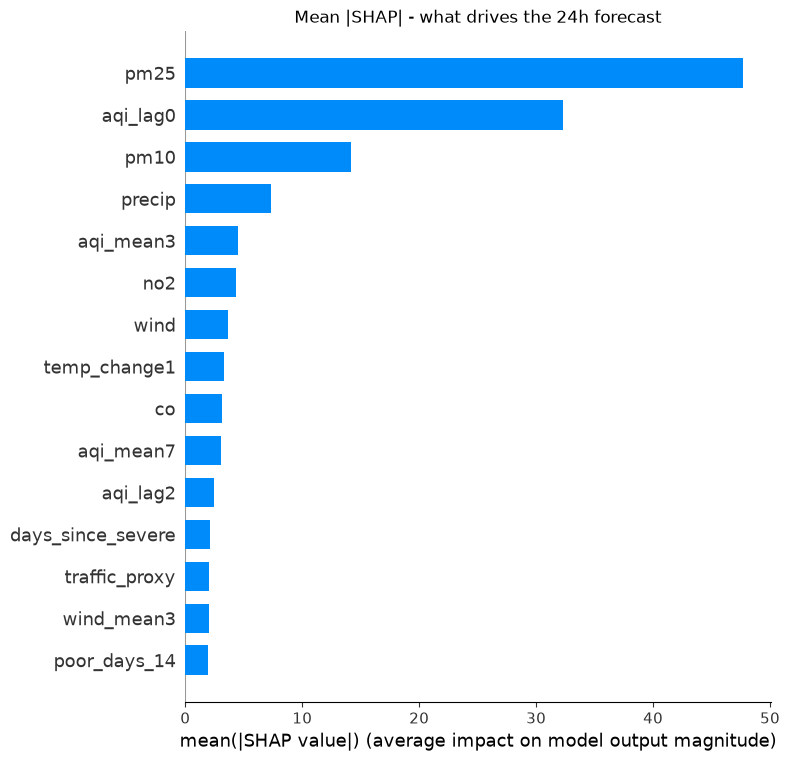

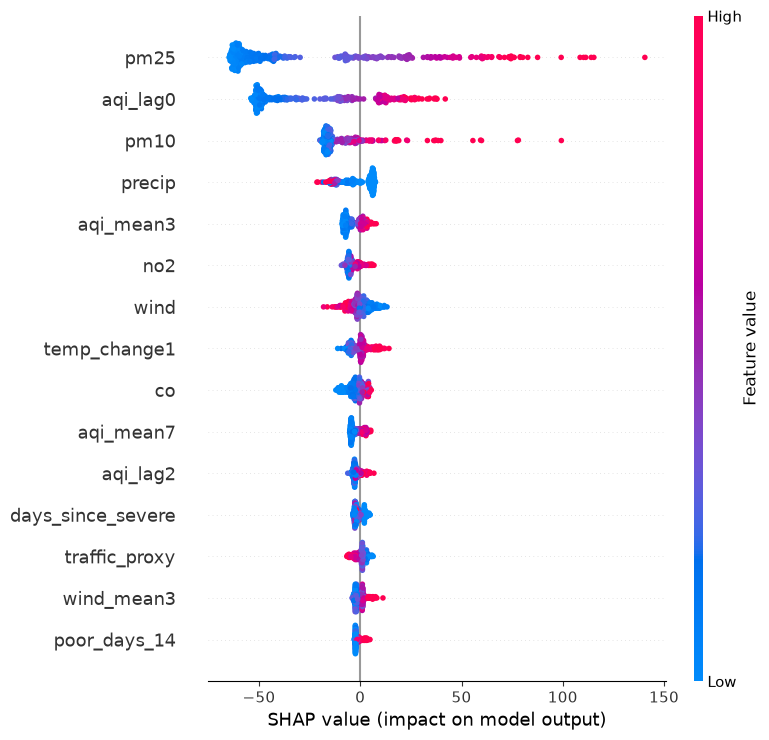

In [2]:
plt.figure()
shap.summary_plot(shap_values[1].values, X, plot_type="bar", max_display=15, show=False)
plt.title("Mean |SHAP| - what drives the 24h forecast")
plt.savefig(FIG_DIR / "shap_bar_h1.png", dpi=150, bbox_inches="tight"); plt.show()

plt.figure()
shap.summary_plot(shap_values[1].values, X, max_display=15, show=False)
plt.savefig(FIG_DIR / "shap_beeswarm_h1.png", dpi=150, bbox_inches="tight"); plt.show()

### Importance by feature group and horizon

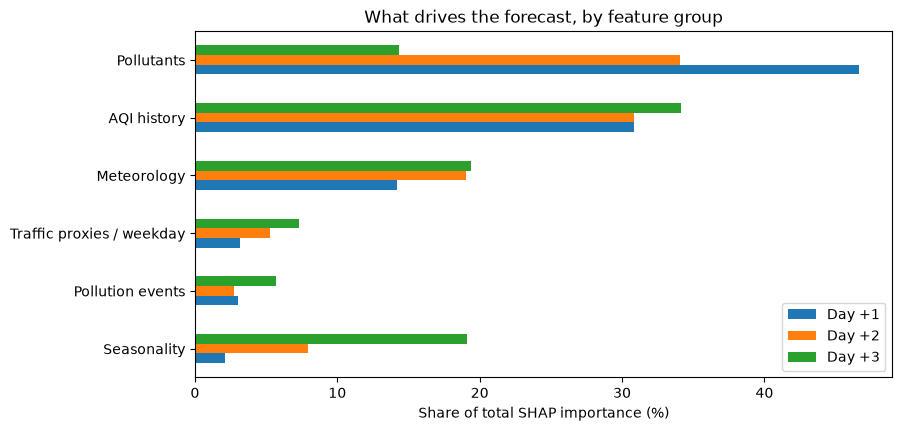

,Day +1,Day +2,Day +3
AQI history,30.799999,30.799999,34.200001
Meteorology,14.200000,19.100000,19.400000
Pollutants,46.700001,34.099998,14.300000
Pollution events,3.000000,2.700000,5.700000
Seasonality,2.100000,8.000000,19.100000
Traffic proxies / weekday,3.100000,5.300000,7.300000


In [3]:
def feature_group(f):
    if f.startswith("aqi_"):
        return "AQI history"
    if f in ("days_since_severe", "poor_days_14", "diwali_window", "stubble_season"):
        return "Pollution events"
    if f in ("pm25", "pm10", "no2", "so2", "co", "o3", "pm25_mean3", "pm_ratio"):
        return "Pollutants"
    if f in ("traffic_proxy", "co_mean3", "is_weekend", "dayofweek"):
        return "Traffic proxies / weekday"
    if f.startswith(("month", "doy")):
        return "Seasonality"
    return "Meteorology"

imp = pd.DataFrame({f"Day +{h}": np.abs(shap_values[h].values).mean(axis=0) for h in HORIZONS},
                   index=feature_cols)
imp.sort_values("Day +1", ascending=False).to_csv(RESULTS_DIR / "shap_importance.csv")

grp = imp.groupby(feature_group).sum()
grp = grp.div(grp.sum()) * 100
ax = grp.sort_values("Day +1").plot.barh(figsize=(9, 4.5))
ax.set_xlabel("Share of total SHAP importance (%)"); ax.set_title("What drives the forecast, by feature group")
plt.savefig(FIG_DIR / "shap_group_importance.png", dpi=150, bbox_inches="tight"); plt.show()
grp.round(1)

### Explaining one specific forecast (the worst-pollution day in the test period)

Date: 2019-11-02 | actual next-day AQI: 659


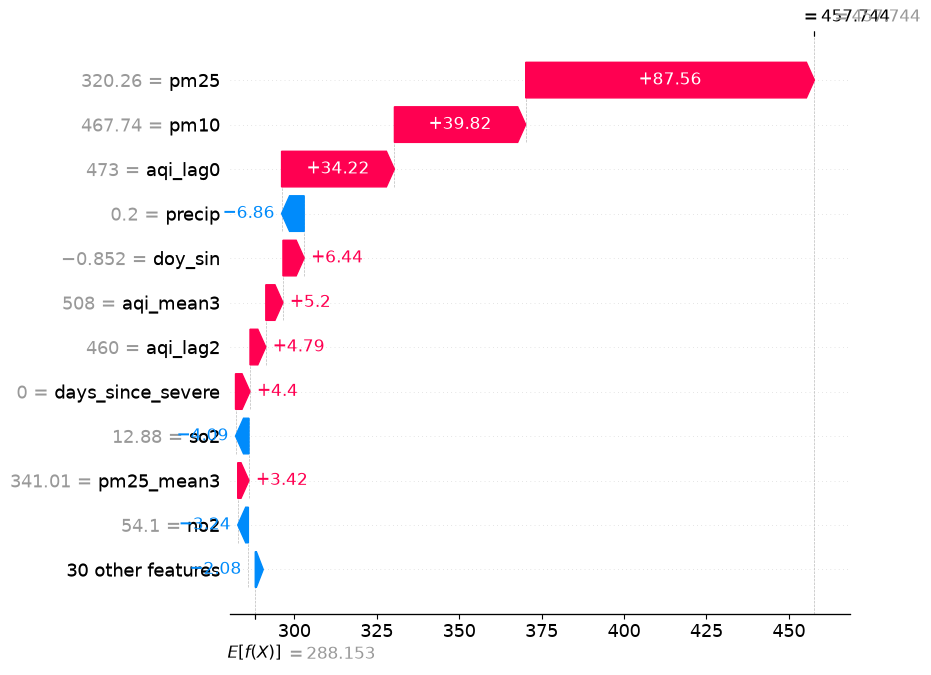

In [4]:
i = int(np.argmax(test["y_h1"].values))
print("Date:", test.index[i].date(), "| actual next-day AQI:", round(test['y_h1'].iloc[i]))
plt.figure()
shap.plots.waterfall(shap_values[1][i], max_display=12, show=False)
plt.savefig(FIG_DIR / "shap_waterfall_example.png", dpi=150, bbox_inches="tight"); plt.show()

### Interpretation notes for the report
* Features that appear at the top are the model's main evidence; red dots (high value) pushing right means "higher value -> higher AQI".
* Expect AQI history (today's AQI, recent average) to dominate - air pollution is very persistent.
* Check whether wind, humidity, season and event features also matter; this supports the claim that engineered features add information beyond persistence.
* SHAP shows **association learned by the model**, not proof of physical causation.